# Day 15 — Robustness of S&P 500 return-magnitude forecasts
Run every cell in order in your finance-volatility project. This is an **exploratory robustness analysis conducted after the 2025 test was viewed**. It does not create another untouched test.

**Two parts:**
1. Use outcomes through 2022 to fit sensitivity models and evaluate them on **2023–2024**. Reuse Day 13's selected hyperparameters without a new search.
2. Use **only saved, frozen Day 14 predictions** to diagnose 2025 performance by quarter and by return-magnitude conditions known at the forecast origin. No 2025 observations enter a new model fit.

Focus on OLS (your Day 12 extended regression in the original scenario), lasso, random forest, EWM, and historical mean. We omit ridge and expanded OLS to keep this diagnostic focused on your main candidates and benchmarks.

**Inputs:** `data/financial_raw_data.csv`; `results/day13_configuration.json`, `day13_tuning_summary.csv`, `day13_validation_predictions.csv`, `day14_frozen_specification.json`, `day14_test_predictions.csv`, and `day14_run_record.json`. Keep the original saved data and files. All new outputs begin with `day15_`.

The code produces your actual results when run locally. It does not contain your market data or claim any new finding in advance.


## 1. Install packages and check paths
If your environment already has these packages, skip installation. After any required kernel restart, continue with imports. Confirm `PROJECT_ROOT` below.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

PROJECT_ROOT = Path('/Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility')
DATA_DIR = PROJECT_ROOT / 'data'
RESULTS_DIR = PROJECT_ROOT / 'results'
FIGURES_DIR = PROJECT_ROOT / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
file_path = DATA_DIR / 'financial_raw_data.csv'
assert file_path.exists(), f'Missing input: {file_path}'

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 2. Load saved choices and reconstruct development features
Filter out dates after 2024 **before** calculating returns or future labels. Features exactly match Day 13. Build them on the complete observed S&P trading sequence before dropping missing VIX/yield inputs. No filling of missing data is used.

At an origin, today's S&P close, VIX close, and yield observation must be available. Historical FRED observations are not verified real-time vintages; this analysis alone cannot establish live availability or exchange-calendar completeness.


In [2]:
required_files = ['day13_configuration.json', 'day13_tuning_summary.csv',
                  'day13_validation_predictions.csv', 'day14_frozen_specification.json',
                  'day14_test_predictions.csv', 'day14_run_record.json']
for filename in required_files:
    assert (RESULTS_DIR / filename).exists(), f'Missing original output: {filename}'
source_hashes = {name: hashlib.sha256((RESULTS_DIR / name).read_bytes()).hexdigest()
                 for name in required_files}
config = json.loads((RESULTS_DIR / 'day13_configuration.json').read_text())
tuning = pd.read_csv(RESULTS_DIR / 'day13_tuning_summary.csv').set_index('method')
frozen14 = json.loads((RESULTS_DIR / 'day14_frozen_specification.json').read_text())
run14 = json.loads((RESULTS_DIR / 'day14_run_record.json').read_text())
assert tuning.index.is_unique
best_params = {name: json.loads(tuning.loc[name, 'best_parameters'])
               for name in ['lasso', 'random_forest']}
assert best_params['lasso'] == frozen14['best_parameters']['lasso']
assert best_params['random_forest'] == frozen14['best_parameters']['random_forest']
assert config['training_outcomes_end'] == frozen14['training_outcomes_end'] == '2022-12-31'
assert config['validation_outcomes'] == ['2023-01-01', '2024-12-31']
assert config['negative_predictions'] == 'Scored unchanged'
assert frozen14['negative_predictions'] == 'Scored unchanged'
day12_features = ['absolute_return', 'mean_abs_5', 'mean_abs_20', 'vix', 'treasury_change']
ml_features = day12_features + ['log_return', 'return_lag_1', 'abs_lag_1', 'abs_lag_5',
                               'squared_return', 'return_std_5', 'return_std_20']
base_columns = ['sp500', 'vix', 'treasury_10yr']
baseline_columns = ['historical_mean', 'ewm_20']
assert config['ml_features'] == ml_features and config['day12_features'] == day12_features
raw_development = pd.read_csv(file_path, parse_dates=['date'])
assert raw_development['date'].notna().all()
raw_development = raw_development.loc[
    raw_development['date'] <= pd.Timestamp('2024-12-31')
].copy()


def build_features(raw_frame, until="2024-12-31"):
    data = raw_frame.copy()
    assert {'date', 'sp500', 'vix', 'treasury_10yr'}.issubset(data.columns)
    assert data['date'].notna().all(), 'Missing/invalid dates.'
    assert not data['date'].duplicated().any(), 'Duplicate dates.'
    data = data.loc[data['date'] <= pd.Timestamp(until)].sort_values('date').reset_index(drop=True)
    base_columns = ['sp500', 'vix', 'treasury_10yr']
    for col in base_columns:
        data[col] = pd.to_numeric(data[col], errors='raise')
    assert not np.isinf(data[base_columns].to_numpy()).any()
    data = data.dropna(subset=['sp500']).reset_index(drop=True)
    assert data['sp500'].gt(0).all()

    data['log_return'] = 100 * np.log(data['sp500']).diff()
    data['absolute_return'] = data['log_return'].abs()
    data['squared_return'] = data['log_return'] ** 2
    data['return_lag_1'] = data['log_return'].shift(1)
    data['abs_lag_1'] = data['absolute_return'].shift(1)
    data['abs_lag_5'] = data['absolute_return'].shift(5)
    for window in [5, 20]:
        data[f'mean_abs_{window}'] = data['absolute_return'].rolling(window, min_periods=window).mean()
        data[f'return_std_{window}'] = data['log_return'].rolling(window, min_periods=window).std(ddof=1)
    data['treasury_change'] = data['treasury_10yr'].diff()
    data['target_next_day'] = data['absolute_return'].shift(-1)
    data['target_date'] = data['date'].shift(-1)
    data['historical_mean'] = data['absolute_return'].expanding(min_periods=20).mean()
    data['ewm_20'] = data['absolute_return'].ewm(span=20, adjust=False, min_periods=20).mean()

    return data

development = build_features(raw_development)
development_hash = hashlib.sha256(
    development[['date', *base_columns]].to_csv(index=False).encode('utf-8')
).hexdigest()
assert development_hash == config['pre2025_sp500_observation_input_sha256'], (
    'Development history differs from Day 13. Use the original saved CSV; do not bypass this check.'
)
assert development_hash == frozen14['pre2025_input_sha256']
display(tuning.loc[['lasso', 'random_forest']])


,mean_fold_RMSE,best_parameters
method,,
lasso,0.721065,"{""model__alpha"": 0.05}"
random_forest,0.732943,"{""max_depth"": 3, ""max_features"": 0.7, ""min_sam..."


## 3. Specify a limited set of checks before running them
All scenarios end training at 2022 and evaluate on 2023–2024. The original model feature sets are OLS = five Day 12 predictors; lasso/forest = twelve Day 13 predictors. Feature removals apply to each model's own original set. Thus an ablation compares each method with itself while removing information; model-to-model comparisons also reflect their differing feature sets.

| Scenario | Change |
|---|---|
| Original | Full available pre-2023 training; next-day absolute log return |
| 2018–2022 window | Five calendar years of training outcomes |
| 2020–2022 window | Three calendar years of training outcomes |
| Without VIX | Remove VIX; hold other features and hyperparameters fixed |
| Without Treasury change | Remove the yield-change predictor |
| Return history only | Remove both VIX and Treasury change |
| Five-day point horizon | Predict absolute return at the fifth future trading observation |
| Five-day mean target | Predict mean absolute return across the next five trading observations |

Compare the last two scenarios to examine a target-definition change at the same five-observation endpoint. They are different forecast tasks; lower raw error for an averaged target does not establish a better model. Fixed lasso/forest settings deliberately test sensitivity of current specifications, not the best achievable tuning for a new target/horizon. No new best model will be chosen automatically.


In [3]:
cutoff = pd.Timestamp('2022-12-31')
original_map = {'ols': day12_features, 'lasso': ml_features, 'random_forest': ml_features}
def remove_features(names):
    return {method: [f for f in features if f not in names]
            for method, features in original_map.items()}
scenarios = [
    {'name': 'original', 'check': 'reference', 'train_start': None,
     'horizon': 1, 'target_kind': 'point', 'feature_map': original_map},
    {'name': 'window_2018_2022', 'check': 'training_window', 'train_start': '2018-01-01',
     'horizon': 1, 'target_kind': 'point', 'feature_map': original_map},
    {'name': 'window_2020_2022', 'check': 'training_window', 'train_start': '2020-01-01',
     'horizon': 1, 'target_kind': 'point', 'feature_map': original_map},
    {'name': 'without_vix', 'check': 'features', 'train_start': None,
     'horizon': 1, 'target_kind': 'point', 'feature_map': remove_features(['vix'])},
    {'name': 'without_treasury', 'check': 'features', 'train_start': None,
     'horizon': 1, 'target_kind': 'point', 'feature_map': remove_features(['treasury_change'])},
    {'name': 'return_history_only', 'check': 'features', 'train_start': None,
     'horizon': 1, 'target_kind': 'point', 'feature_map': remove_features(['vix', 'treasury_change'])},
    {'name': 'point_horizon_5', 'check': 'horizon', 'train_start': None,
     'horizon': 5, 'target_kind': 'point', 'feature_map': original_map},
    {'name': 'mean_next_5', 'check': 'target_definition', 'train_start': None,
     'horizon': 5, 'target_kind': 'mean', 'feature_map': original_map},
]
protocol = {
    'analysis': 'Exploratory robustness after final 2025 test was viewed',
    'scenarios': scenarios, 'training_outcomes_end': '2022-12-31',
    'evaluation_outcomes': ['2023-01-01', '2024-12-31'],
    'negative_forecasts': 'Scored unchanged', 'best_parameters': best_params,
    'forest_n_estimators': config['random_forest_n_estimators'],
    'random_state': config['random_state'],
    'new_tuning': False, 'new_fitting_on_2025': False,
    'origin_condition_rule': 'EWM at origin above pre-2023 training median versus at/below',
    'source_hashes': source_hashes, 'development_input_sha256': development_hash,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'scikit_learn': sklearn.__version__},
}
protocol_path = RESULTS_DIR / 'day15_protocol.json'
if protocol_path.exists():
    assert json.loads(protocol_path.read_text()) == protocol, (
        'Existing Day 15 protocol differs. Preserve and investigate the previous analysis.'
    )
else:
    protocol_path.write_text(json.dumps(protocol, indent=2), encoding='utf-8')
display(pd.DataFrame(scenarios)[['name', 'check', 'train_start', 'horizon', 'target_kind']])


,name,check,train_start,horizon,target_kind
0,original,reference,NaN,1,point
1,window_2018_2022,training_window,2018-01-01,1,point
2,window_2020_2022,training_window,2020-01-01,1,point
3,without_vix,features,NaN,1,point
4,without_treasury,features,NaN,1,point
5,return_history_only,features,NaN,1,point
6,point_horizon_5,horizon,NaN,5,point
7,mean_next_5,target_definition,NaN,5,mean


## 4. Define labels, fitting, and scoring functions
For horizon h, a point label is |r(t+h)| and its date is the h-th future S&P observation. For the mean target, the label is the average of |r(t+1)| through |r(t+h)|. A label is eligible for training only when its **endpoint** is at or before December 31, 2022. This removes training labels that extend into validation.

For each task, retain common rows using the full original feature set before feature removal. This prevents an apparent gain merely from changing eligible dates. For five-day forecasts, the first 2023 outcomes have origins in late 2022: also exclude training labels that are not yet observed at the first validation origin. The EWM/historical mean at the origin are benchmarks for future daily magnitudes; for the mean target they correspond to forecasting the same expected daily magnitude for each future day and averaging it.

Preprocessing is fitted on training rows inside pipelines, as recommended in [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html). Hyperparameters are taken from the original training-only search. See [Lasso documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html).


In [4]:
methods = baseline_columns + ['ols', 'lasso', 'random_forest']
def make_task(features, horizon, target_kind):
    frame = features.copy()
    frame['outcome_date'] = frame['date'].shift(-horizon)
    if target_kind == 'point':
        frame['actual'] = frame['absolute_return'].shift(-horizon)
        frame['outcome_start_date'] = frame['outcome_date']
    elif target_kind == 'mean':
        future_returns = pd.concat(
            [frame['absolute_return'].shift(-j) for j in range(1, horizon + 1)], axis=1)
        frame['actual'] = future_returns.mean(axis=1, skipna=False)
        frame['outcome_start_date'] = frame['date'].shift(-1)
    else:
        raise ValueError(target_kind)
    frame = frame.dropna(subset=ml_features + baseline_columns +
                        ['actual', 'outcome_date', 'outcome_start_date']).copy()
    assert (frame['date'] < frame['outcome_start_date']).all()
    assert (frame['outcome_start_date'] <= frame['outcome_date']).all()
    assert np.isfinite(frame[ml_features + baseline_columns + ['actual']].to_numpy()).all()
    return frame

def scaled_model(estimator):
    return Pipeline([('scaler', StandardScaler()), ('model', estimator)])

def evaluate(frame):
    rows = []
    for method in methods:
        error = frame[method] - frame['actual']
        rows.append({'method': method, 'n_forecasts': len(frame),
                     'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean()),
                     'Bias': error.mean(), 'negative_forecasts': int((frame[method] < 0).sum())})
    scores = pd.DataFrame(rows)
    for metric in ['MAE', 'RMSE']:
        reference = scores.set_index('method').loc['ewm_20', metric]
        assert reference > 0
        scores[f'{metric}_improvement_vs_ewm_pct'] = 100 * (1 - scores[metric] / reference)
    return scores

def run_scenario(spec):
    task = make_task(development, spec['horizon'], spec['target_kind'])
    val_rows = task.loc[task['outcome_date'].between('2023-01-01', '2024-12-31')].copy()
    assert not val_rows.empty
    effective_cutoff = min(cutoff, val_rows['date'].min())
    fit_rows = task.loc[task['outcome_date'] <= effective_cutoff].copy()
    if spec['train_start'] is not None:
        fit_rows = fit_rows.loc[fit_rows['outcome_date'] >= pd.Timestamp(spec['train_start'])].copy()
    assert len(fit_rows) > 100 and not val_rows.empty
    assert fit_rows['outcome_date'].max() <= cutoff
    # Every training label is available by the first validation forecast origin.
    assert fit_rows['outcome_date'].max() <= val_rows['date'].min()
    fitted = {
        'ols': LinearRegression(),
        'lasso': scaled_model(Lasso(max_iter=50000, tol=1e-5)).set_params(**best_params['lasso']),
        'random_forest': RandomForestRegressor(
            n_estimators=config['random_forest_n_estimators'],
            random_state=config['random_state'], n_jobs=1
        ).set_params(**best_params['random_forest']),
    }
    predictions = val_rows[['date', 'outcome_start_date', 'outcome_date', 'actual', *baseline_columns]].copy()
    for method, model in fitted.items():
        features = spec['feature_map'][method]
        model.fit(fit_rows[features], fit_rows['actual'])
        predictions[method] = model.predict(val_rows[features])
        if method == 'lasso':
            assert model.named_steps['scaler'].n_samples_seen_ == len(fit_rows)
    assert np.isfinite(predictions[methods].to_numpy()).all()
    scores = evaluate(predictions)
    scores.insert(0, 'scenario', spec['name'])
    scores.insert(1, 'check', spec['check'])
    scores['training_rows'] = len(fit_rows)
    scores['training_outcome_start'] = fit_rows['outcome_date'].min()
    scores['training_outcome_end'] = fit_rows['outcome_date'].max()
    scores['effective_training_cutoff'] = effective_cutoff
    scores['validation_outcome_start'] = val_rows['outcome_date'].min()
    scores['validation_outcome_end'] = val_rows['outcome_date'].max()
    scores['horizon'] = spec['horizon']
    scores['target_kind'] = spec['target_kind']
    scores['error_units'] = 'percentage points'
    scores['n_features'] = scores['method'].map(
        {name: len(features) for name, features in spec['feature_map'].items()}).fillna(0).astype(int)
    predictions.insert(0, 'scenario', spec['name'])
    return scores, predictions, fit_rows


## 5. Reproduce the original validation forecasts, then run checks
The original scenario must reproduce the saved Day 13 OLS/lasso/forest and baseline forecasts before the variants are evaluated. A mismatch means input, parameter, or environment differences need investigation. Do not loosen tolerances to proceed.

There is one fixed fit per method per scenario, with no search over parameters. Different horizons can have different eligible dates because forecast origins differ; dates are identical across methods within every scenario. Window/feature checks have exactly the original validation dates.


In [5]:
original_scores, original_predictions, original_train = run_scenario(scenarios[0])
saved13 = pd.read_csv(RESULTS_DIR / 'day13_validation_predictions.csv',
                      parse_dates=['date', 'target_date']).rename(
    columns={'target_date': 'outcome_date', 'target_next_day': 'actual', 'day12_extended': 'ols'})
original_sorted = original_predictions.sort_values('outcome_date').reset_index(drop=True)
saved_sorted = saved13.sort_values('outcome_date').reset_index(drop=True)
pd.testing.assert_frame_equal(original_sorted[['date', 'outcome_date']],
                              saved_sorted[['date', 'outcome_date']])
np.testing.assert_allclose(original_sorted[methods + ['actual']], saved_sorted[methods + ['actual']],
                           rtol=1e-8, atol=1e-8, err_msg='Original forecasts not reproduced.')
assert len(original_train) == config['ml_training_rows']
assert len(original_predictions) == config['validation_rows']
print('Original forecasts reproduced. Running seven sensitivity scenarios...')
score_tables = [original_scores]
prediction_tables = [original_predictions]
fit_summaries = []
for spec in scenarios:
    if spec['name'] == 'original':
        scores, predictions, fit_rows = original_scores, original_predictions, original_train
    else:
        scores, predictions, fit_rows = run_scenario(spec)
        score_tables.append(scores)
        prediction_tables.append(predictions)
    if spec['check'] in ['training_window', 'features']:
        pd.testing.assert_frame_equal(
            predictions[['date', 'outcome_date']].reset_index(drop=True),
            original_predictions[['date', 'outcome_date']].reset_index(drop=True))
    fit_summaries.append({'scenario': spec['name'], 'training_rows': len(fit_rows),
                          'last_training_origin': fit_rows['date'].max(),
                          'last_training_label_end': fit_rows['outcome_date'].max(),
                          'first_validation_origin': predictions['date'].min(),
                          'n_forecasts': len(predictions)})
    print(spec['name'], '| training:', len(fit_rows), '| forecasts:', len(predictions))
robustness = pd.concat(score_tables, ignore_index=True)
robustness_predictions = pd.concat(prediction_tables, ignore_index=True)
fit_audit = pd.DataFrame(fit_summaries)
display(robustness[['scenario', 'method', 'n_forecasts', 'MAE', 'RMSE', 'Bias',
                    'RMSE_improvement_vs_ewm_pct']].round(4))

within_task_rankings = robustness.loc[robustness.groupby('scenario')['RMSE'].idxmin(),
    ['scenario', 'method', 'RMSE', 'RMSE_improvement_vs_ewm_pct']].rename(columns={'method': 'lowest_RMSE_method'})
display(within_task_rankings.round(4))
print('Rankings are diagnostic; no new final model is selected from these checks.')


Original forecasts reproduced. Running seven sensitivity scenarios...
original | training: 1528 | forecasts: 496
window_2018_2022 | training: 1239 | forecasts: 496
window_2020_2022 | training: 744 | forecasts: 496
without_vix | training: 1528 | forecasts: 496
without_treasury | training: 1528 | forecasts: 496
return_history_only | training: 1528 | forecasts: 496
point_horizon_5 | training: 1520 | forecasts: 496
mean_next_5 | training: 1520 | forecasts: 496


,scenario,method,n_forecasts,MAE,RMSE,Bias,RMSE_improvement_vs_ewm_pct
0,original,historical_mean,496,0.4591,0.5471,0.1425,-3.2057
1,original,ewm_20,496,0.4229,0.5301,0.0037,0.0000
2,original,ols,496,0.4153,0.5261,-0.0325,0.7532
3,original,lasso,496,0.4127,0.5182,-0.0113,2.2420
4,original,random_forest,496,0.4065,0.5180,-0.0416,2.2849
5,window_2018_2022,historical_mean,496,0.4591,0.5471,0.1425,-3.2057
6,window_2018_2022,ewm_20,496,0.4229,0.5301,0.0037,0.0000
7,window_2018_2022,ols,496,0.4154,0.5287,-0.0471,0.2673
8,window_2018_2022,lasso,496,0.4140,0.5195,-0.0083,1.9972
9,window_2018_2022,random_forest,496,0.4110,0.5156,-0.0073,2.7362


,scenario,lowest_RMSE_method,RMSE,RMSE_improvement_vs_ewm_pct
39,mean_next_5,random_forest,0.2318,11.0918
4,original,random_forest,0.5180,2.2849
33,point_horizon_5,lasso,0.5223,1.4618
28,return_history_only,lasso,0.5274,0.5162
9,window_2018_2022,random_forest,0.5156,2.7362
14,window_2020_2022,random_forest,0.5159,2.6861
23,without_treasury,lasso,0.5168,2.5147
18,without_vix,lasso,0.5294,0.1341


Rankings are diagnostic; no new final model is selected from these checks.


## 6. Diagnose stability by year/quarter and origin conditions
Use the original validation forecasts and the saved Day 14 test forecasts. All new scenario results remain confined to development data.

Higher/lower conditions are defined by **EWM at the forecast origin**, using the median EWM among the original pre-2023 training rows as a fixed threshold. This is a forecast-time proxy for return-magnitude conditions, not a regime assigned from a future outcome. Small groups have noisy scores, so always report counts. The 2025 analysis is descriptive: it cannot be used to retune and then claim a fresh final test.


In [6]:
origin_ewm_threshold = float(original_train['ewm_20'].median())
saved14 = pd.read_csv(RESULTS_DIR / 'day14_test_predictions.csv',
                      parse_dates=['date', 'target_date']).rename(
    columns={'target_date': 'outcome_date', 'target_next_day': 'actual', 'day12_extended': 'ols'})
assert len(saved14) == run14['test_rows']
assert saved14['outcome_date'].dt.year.eq(2025).all()
assert saved14['outcome_date'].is_unique
assert (saved14['date'] < saved14['outcome_date']).all()
assert np.isfinite(saved14[methods + ['actual']].to_numpy()).all()
assert str(saved14['outcome_date'].min().date()) == run14['test_outcome_first']
assert str(saved14['outcome_date'].max().date()) == run14['test_outcome_last']

def group_diagnostics(frame, sample):
    diagnostics = []
    groups = {
        'overall': pd.Series('all', index=frame.index),
        'year': frame['outcome_date'].dt.year.astype(str),
        'quarter': frame['outcome_date'].dt.to_period('Q').astype(str),
        'origin_conditions': pd.Series(np.where(frame['ewm_20'] > origin_ewm_threshold,
                                        'higher_origin_ewm', 'lower_origin_ewm'), index=frame.index),
    }
    for grouping, labels in groups.items():
        for label in sorted(labels.unique()):
            subset = frame.loc[labels == label]
            scores = evaluate(subset)
            scores.insert(0, 'sample', sample)
            scores.insert(1, 'grouping', grouping)
            scores.insert(2, 'group', label)
            scores['outcome_start'] = subset['outcome_date'].min()
            scores['outcome_end'] = subset['outcome_date'].max()
            diagnostics.append(scores)
    return pd.concat(diagnostics, ignore_index=True)

stability = pd.concat([
    group_diagnostics(original_predictions, 'validation_2023_2024'),
    group_diagnostics(saved14, 'frozen_test_2025'),
], ignore_index=True)
print('Origin EWM threshold from pre-2023 training:', round(origin_ewm_threshold, 4))
display(stability.loc[stability['grouping'].isin(['year', 'origin_conditions']),
    ['sample', 'grouping', 'group', 'method', 'n_forecasts', 'MAE', 'RMSE',
     'RMSE_improvement_vs_ewm_pct']].round(4))
display(stability.loc[(stability['sample'] == 'frozen_test_2025') & (stability['grouping'] == 'quarter'),
    ['group', 'method', 'n_forecasts', 'MAE', 'RMSE', 'Bias']].round(4))


Origin EWM threshold from pre-2023 training: 0.6223


,sample,grouping,group,method,n_forecasts,MAE,RMSE,RMSE_improvement_vs_ewm_pct
5,validation_2023_2024,year,2023,historical_mean,248,0.4600,0.5323,-2.4108
6,validation_2023_2024,year,2023,ewm_20,248,0.4328,0.5197,0.0000
7,validation_2023_2024,year,2023,ols,248,0.4258,0.5224,-0.5132
8,validation_2023_2024,year,2023,lasso,248,0.4210,0.5087,2.1206
9,validation_2023_2024,year,2023,random_forest,248,0.4139,0.5076,2.3326
10,validation_2023_2024,year,2024,historical_mean,248,0.4582,0.5616,-3.9359
11,validation_2023_2024,year,2024,ewm_20,248,0.4130,0.5403,0.0000
12,validation_2023_2024,year,2024,ols,248,0.4048,0.5298,1.9397
13,validation_2023_2024,year,2024,lasso,248,0.4044,0.5276,2.3546
14,validation_2023_2024,year,2024,random_forest,248,0.3991,0.5282,2.2409


,group,method,n_forecasts,MAE,RMSE,Bias
75,2025Q1,historical_mean,60,0.5051,0.6242,-0.0772
76,2025Q1,ewm_20,60,0.5052,0.6236,-0.0450
77,2025Q1,ols,60,0.4783,0.5980,-0.0582
78,2025Q1,lasso,60,0.4895,0.6004,-0.0556
79,2025Q1,random_forest,60,0.4835,0.6101,-0.0893
80,2025Q2,historical_mean,62,0.8314,1.5747,-0.3440
81,2025Q2,ewm_20,62,0.8986,1.4954,0.0600
82,2025Q2,ols,62,0.8380,1.3709,-0.0187
83,2025Q2,lasso,62,0.8498,1.4419,-0.0374
84,2025Q2,random_forest,62,0.9112,1.4722,0.1079


## 7. Audit timing, leakage, and selection limits
The automatic perturbation check changes later development prices, VIX, and yields and verifies that earlier predictors and baselines stay identical. Future labels must change when appropriate; they are excluded from this predictor check. The label-end audit ensures every longer-horizon training response matured before validation forecasting.

These checks verify this code's timing rules. They do not prove exchange-calendar completeness or that historical values were available in real time. Validation has already been inspected; these additional analyses are exploratory, and choosing many variations can produce unstable apparent winners. No statistical superiority claim follows from the smallest table entry.


In [7]:
perturbed = raw_development.copy()
perturb_after = pd.Timestamp('2024-06-30')
later = perturbed['date'] > perturb_after
perturbed.loc[later, 'sp500'] *= 1.5
perturbed.loc[later, 'vix'] += 10
perturbed.loc[later, 'treasury_10yr'] += 2
perturbed_features = build_features(perturbed)
earlier = development['date'] <= perturb_after
pd.testing.assert_frame_equal(
    development.loc[earlier, ml_features + baseline_columns],
    perturbed_features.loc[earlier, ml_features + baseline_columns])
assert fit_audit['last_training_label_end'].le(cutoff).all()
assert (fit_audit['last_training_label_end'] <= fit_audit['first_validation_origin']).all()
assert all((RESULTS_DIR / name).exists() for name in required_files)
assert {name: hashlib.sha256((RESULTS_DIR / name).read_bytes()).hexdigest()
        for name in required_files} == source_hashes, 'Original result files changed during analysis.'
audit = pd.DataFrame([
    {'check': 'Original development data and validation forecasts reproduced', 'status': 'Passed',
     'evidence': 'Input fingerprint and saved prediction comparison'},
    {'check': 'Future observations do not change earlier features', 'status': 'Passed',
     'evidence': 'Perturbation of later prices, VIX, and yields'},
    {'check': 'All training responses mature before validation forecasting', 'status': 'Passed',
     'evidence': 'Outcome-end cutoff checks, including five-day mean labels'},
    {'check': 'Scaler fitted on training rows only', 'status': 'Passed',
     'evidence': 'Pipeline fitted only on fit_rows; sample count asserted'},
    {'check': 'Common evaluation dates', 'status': 'Passed',
     'evidence': 'Within-scenario methods share rows; window/feature dates match original'},
    {'check': 'No new model uses 2025 for fitting or tuning', 'status': 'Passed',
     'evidence': 'Development ends in 2024; all fits end in 2022; test diagnostics use saved CSV'},
    {'check': 'Original saved result files preserved', 'status': 'Passed', 'evidence': 'File hashes unchanged'},
    {'check': 'Real-time information availability and calendar completeness', 'status': 'Not established',
     'evidence': 'Historical FRED CSV is not a verified real-time vintage or exchange calendar'},
    {'check': 'Selection stability and superiority', 'status': 'Interpretation required',
     'evidence': 'Eight limited scenarios; validation previously viewed; uncertainty not quantified'},
])
display(fit_audit)
display(audit)


,scenario,training_rows,last_training_origin,last_training_label_end,first_validation_origin,n_forecasts
0,original,1528,2022-12-29,2022-12-30,2022-12-30,496
1,window_2018_2022,1239,2022-12-29,2022-12-30,2022-12-30,496
2,window_2020_2022,744,2022-12-29,2022-12-30,2022-12-30,496
3,without_vix,1528,2022-12-29,2022-12-30,2022-12-30,496
4,without_treasury,1528,2022-12-29,2022-12-30,2022-12-30,496
5,return_history_only,1528,2022-12-29,2022-12-30,2022-12-30,496
6,point_horizon_5,1520,2022-12-16,2022-12-23,2022-12-23,496
7,mean_next_5,1520,2022-12-16,2022-12-23,2022-12-23,496


,check,status,evidence
0,Original development data and validation forec...,Passed,Input fingerprint and saved prediction comparison
1,Future observations do not change earlier feat...,Passed,"Perturbation of later prices, VIX, and yields"
2,All training responses mature before validatio...,Passed,"Outcome-end cutoff checks, including five-day ..."
3,Scaler fitted on training rows only,Passed,Pipeline fitted only on fit_rows; sample count...
4,Common evaluation dates,Passed,Within-scenario methods share rows; window/fea...
5,No new model uses 2025 for fitting or tuning,Passed,Development ends in 2024; all fits end in 2022...
6,Original saved result files preserved,Passed,File hashes unchanged
7,Real-time information availability and calenda...,Not established,Historical FRED CSV is not a verified real-tim...
8,Selection stability and superiority,Interpretation required,Eight limited scenarios; validation previously...


## 8. Plot and save the robustness outputs
The first figure compares RMSE improvement versus EWM within each scenario. The second shows the original target's quarterly improvement from saved validation/test forecasts. A bar above zero means lower error than EWM in that same task/group. Bar heights do not establish statistical significance. Review group counts in the tables before interpreting quarters or conditions.


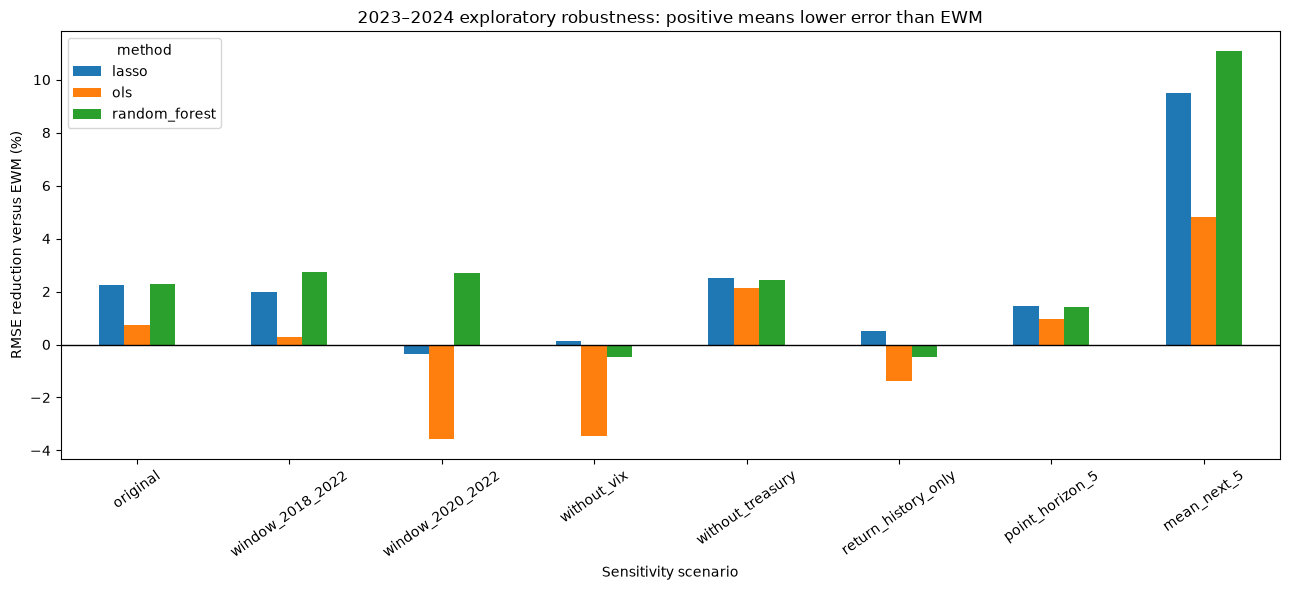

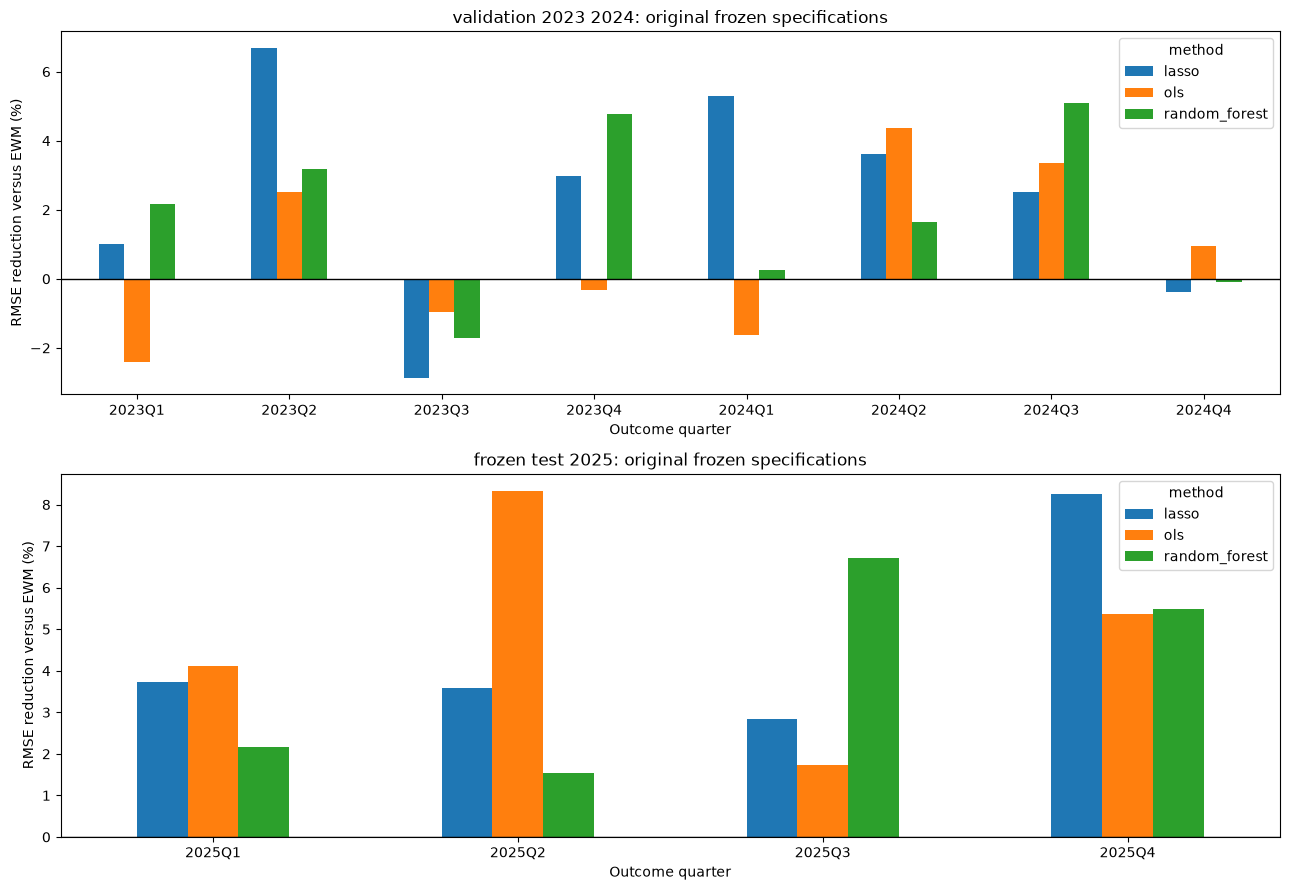

Day 15 results saved to: /Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility/results
Figures saved to: /Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility/figures


In [8]:
fig, ax = plt.subplots(figsize=(13, 6))
relative = robustness.loc[robustness['method'].isin(['ols', 'lasso', 'random_forest'])].pivot(
    index='scenario', columns='method', values='RMSE_improvement_vs_ewm_pct').reindex(
        [spec['name'] for spec in scenarios])
relative.plot(kind='bar', ax=ax)
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel('RMSE reduction versus EWM (%)')
ax.set_xlabel('Sensitivity scenario')
ax.set_title('2023–2024 exploratory robustness: positive means lower error than EWM')
ax.tick_params(axis='x', labelrotation=35)
save_figure(fig, 'day15_robustness_comparison.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for ax, sample in zip(axes, ['validation_2023_2024', 'frozen_test_2025']):
    quarterly = stability.loc[(stability['sample'] == sample) & (stability['grouping'] == 'quarter')
        & stability['method'].isin(['ols', 'lasso', 'random_forest'])].pivot(
            index='group', columns='method', values='RMSE_improvement_vs_ewm_pct')
    quarterly.plot(kind='bar', ax=ax)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_ylabel('RMSE reduction versus EWM (%)')
    ax.set_xlabel('Outcome quarter')
    ax.set_title(sample.replace('_', ' ') + ': original frozen specifications')
    ax.tick_params(axis='x', labelrotation=0)
save_figure(fig, 'day15_quarterly_stability.png')

robustness.to_csv(RESULTS_DIR / 'day15_robustness_results.csv', index=False)
robustness_predictions.to_csv(RESULTS_DIR / 'day15_validation_predictions.csv', index=False)
within_task_rankings.to_csv(RESULTS_DIR / 'day15_scenario_rankings.csv', index=False)
stability.to_csv(RESULTS_DIR / 'day15_subperiod_diagnostics.csv', index=False)
fit_audit.to_csv(RESULTS_DIR / 'day15_training_timing_audit.csv', index=False)
audit.to_csv(RESULTS_DIR / 'day15_methodology_audit.csv', index=False)
record = {'protocol': protocol, 'origin_ewm_threshold': origin_ewm_threshold,
          'robustness_result_rows': len(robustness),
          'original_validation_rows': len(original_predictions),
          'frozen_test_rows': len(saved14),
          'test_results_source': 'Original day14_test_predictions.csv; no new test forecasts',
          'original_sources_preserved': True}
(RESULTS_DIR / 'day15_run_record.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
print('Day 15 results saved to:', RESULTS_DIR)
print('Figures saved to:', FIGURES_DIR)


**Your Day 15 results show that model rankings depend on the training window, predictors, target, and evaluation period. VIX contributed useful forecasting information, but no model was consistently best.**

I recalculated MAE, RMSE, and bias from your uploaded validation predictions; they match your saved results.

The table below shows **RMSE reduction relative to EWM** on 2023–2024 validation data. Positive values mean better performance than EWM. Every scenario contains **496 forecasts**, aligned across methods within that scenario. Here, OLS means your extended regression, with the scenario’s specified changes.

| Scenario | OLS | Lasso | Random forest |
|---|---:|---:|---:|
| Original setup | 0.75% | 2.24% | **2.28%** |
| Train on 2018–2022 | 0.27% | 2.00% | **2.74%** |
| Train on 2020–2022 | −3.59% | −0.35% | **2.69%** |
| Remove VIX | −3.46% | **0.13%** | −0.47% |
| Remove Treasury changes | 2.13% | **2.51%** | 2.44% |
| Return history only | −1.39% | **0.52%** | −0.46% |
| Predict fifth trading day’s magnitude | 0.96% | **1.46%** | 1.42% |
| Predict next five days’ average magnitude | 4.80% | 9.49% | **11.09%** |

**1. Random forest held up best when you shortened training history.**

It had the lowest MAE and RMSE under all three training windows.

With training restricted to **2020–2022**, OLS and lasso had worse RMSE than EWM. OLS also underpredicted by **0.1437 percentage points on average** and produced **two negative forecasts**—an undesirable result for a nonnegative target.

This supports forest’s relative stability across these windows. It does not establish a universally optimal training window.

**2. VIX helped; Treasury changes did not improve this validation comparison.**

Removing VIX increased both MAE and RMSE for all three fitted models. OLS then performed worse than EWM, while lasso and forest were close to the benchmark.

Removing Treasury changes slightly improved both metrics for all three models. For OLS, RMSE fell from **0.5261 to 0.5188**.

The defensible interpretation is that **VIX added useful information in these specifications**, while Treasury changes provided no observed validation benefit. This does not establish causality or show that Treasury information is always unhelpful.

**3. Forecasting a five-day average produced larger relative gains.**

Forest reduced RMSE by **11.09%** versus EWM for the average absolute return over the next five trading days; lasso reduced it by **9.49%**.

That is a different, smoother target. Its lower raw RMSE cannot be directly interpreted as an improvement in next-day forecasting. It is also an **average of daily magnitudes**, rather than a cumulative five-day return.

For the fifth trading day’s individual magnitude, lasso and forest remained almost tied.

**4. Quarterly performance confirms that the advantage varies over time.**

During validation, forest beat EWM on RMSE in **six of eight quarters**. All three fitted models lost to EWM in **2023Q3**.

In the frozen 2025 results, all three beat EWM on RMSE in every quarter, but their rankings changed:

- **OLS led in Q1 and Q2.**
- **Random forest led in Q3.**
- **Lasso led in Q4.**

MAE tells a less uniform story: forest lost to EWM in **2025Q2**, while OLS and lasso lost in **Q3**. Your conclusion should therefore specify the metric.

**5. The recorded audit passed its computational checks, with two limits remaining.**

It reports successful forecast reproduction, feature-timing checks, training-only scaling, aligned evaluation dates, and preservation of the original files. The five-day scenarios also restricted training labels to those available by the earlier forecast origin.

However, **actual real-time data availability and calendar completeness remain unverified**, and the uncertainty in model differences has not been quantified. These checks remain exploratory because validation and 2025 results had already been viewed; hyperparameters were held fixed.

**Day 15’s analysis is complete.** Save the interpretation in your notebook: the strongest conclusion is that forecasting gains are sensitive to specification and period, with VIX contributing useful information and no consistently superior model. Preserve the original 2025 evaluation when documenting these findings.
